# 03 · Exploratory Data Analysis (EDA)

**EDA** = looking at the clean data from many angles to find patterns, differences and surprises *before* drawing conclusions.

**Input:** `data/processed/sales_cleaned.csv`
**Output:** charts in `visualizations/` + a list of observed facts → used by `04_business_analysis.ipynb` and the Power BI dashboard.

### Ground rules for this notebook
* Every chart answers **one business question**. No decorative charts.
* Ratios are always **weighted**: margin = `SUM(Profit) / SUM(Sales)`.
* We separate **what we observe** (fact) from **why it might happen** (hypothesis). Correlation is never presented as cause.
* Chart code lives in `src/eda.py`, so the same charts are produced by the pipeline and saved as PNGs.

### Libraries
* **pandas** — grouping and summarising (`groupby`, `pivot_table`)
* **NumPy** — numeric helpers (log scale, percentiles)
* **Matplotlib** — the drawing engine behind every chart
* **Seaborn** — built on Matplotlib; used here for the heatmap

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import eda
from utils import CLEAN_FILE, set_chart_style, money

%matplotlib inline
set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

df = pd.read_csv(CLEAN_FILE, parse_dates=["Order Date", "Ship Date"])
print(f"{len(df):,} order lines | {df['Order ID'].nunique():,} orders | "
      f"{df['Order Date'].min():%Y-%m-%d} to {df['Order Date'].max():%Y-%m-%d}")

11,461 order lines | 5,190 orders | 2021-01-01 to 2024-12-31


## 0 · Headline KPIs and the shape of the data

In [2]:
eda.kpi_summary(df).to_frame("value")

,value
Total Sales,"4,391,176.00"
Total Profit,"452,068.04"
Profit Margin %,10.29
Total Orders,"5,190.00"
Total Quantity,"56,703.00"
Average Order Value,846.08
Customers,741.00
YoY Sales Growth % (2024),6.69
YoY Profit Growth % (2024),-6.63


### How are order-line sales distributed?
Before comparing averages we need to know whether "average" is even meaningful.

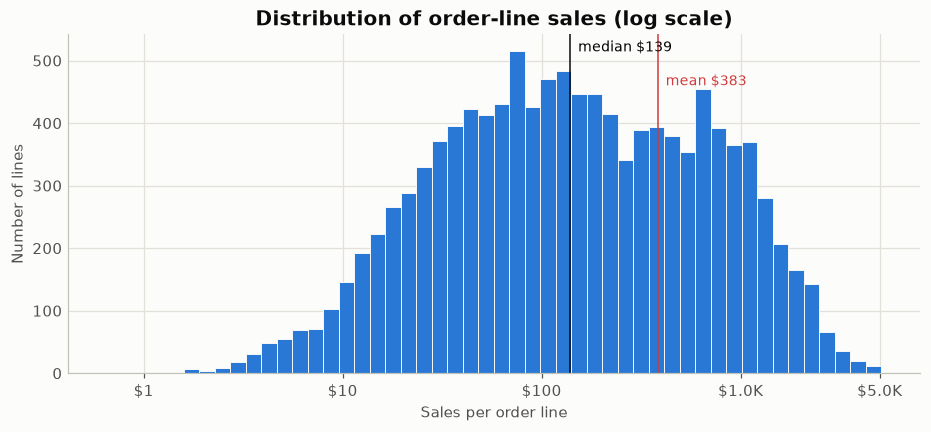

mean     383.14
50%      139.00
std      562.39
min        0.65
max    5,105.04
Name: Sales, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.log10(df["Sales"]), bins=50, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.6)
ticks = [1, 10, 100, 1_000, 5_000]
ax.set_xticks(np.log10(ticks), [money(t) for t in ticks])
ax.axvline(np.log10(df["Sales"].median()), color="#0b0b0b", linewidth=1)
ax.axvline(np.log10(df["Sales"].mean()), color="#d03b3b", linewidth=1)
ax.text(np.log10(df["Sales"].median()), ax.get_ylim()[1] * 0.95, f"  median {money(df['Sales'].median())}", fontsize=9)
ax.text(np.log10(df["Sales"].mean()), ax.get_ylim()[1] * 0.85, f"  mean {money(df['Sales'].mean())}", fontsize=9, color="#d03b3b")
ax.set_title("Distribution of order-line sales (log scale)")
ax.set_xlabel("Sales per order line")
ax.set_ylabel("Number of lines")
plt.show()
df["Sales"].describe()[["mean", "50%", "std", "min", "max"]]

| | |
|---|---|
| **Business question** | Is a typical order line small or large? Can we trust the average? |
| **Variables** | `Sales` per line |
| **Why this chart type** | A histogram shows how values are spread. A **log scale** is used because values range from under $1 to over $5,000; on a normal scale everything would be squashed against the left edge. |
| **What it shows** | Most lines are small (median ≈ $139) but a long tail of expensive lines pulls the **mean (≈ $383) to almost 3× the median**. |
| **How to read it** | Each bar counts lines in a price range. The further the mean is from the median, the more skewed the data. |
| **Possible implication** | Data is **right-skewed**. Use the median (or totals) to describe a 'typical' line. Revenue is driven by a minority of high-value lines — which is why notebook 02 kept outliers. |

---
## 1 · Regional performance

In [4]:
region = eda.summarize_by(df, "Region")
region

,Sales,Profit,Quantity,Orders,Profit Margin %,Sales Share %,Effective Discount %
Region,,,,,,,
West,"1,512,745.30","185,569.64",18898,1731,12.27,34.45,13.47
East,"1,195,924.92","158,222.01",15166,1422,13.23,27.23,13.46
Central,"892,318.30","29,294.54",12601,1131,3.28,20.32,21.51
South,"790,187.48","78,981.85",10038,906,10.00,17.99,15.01


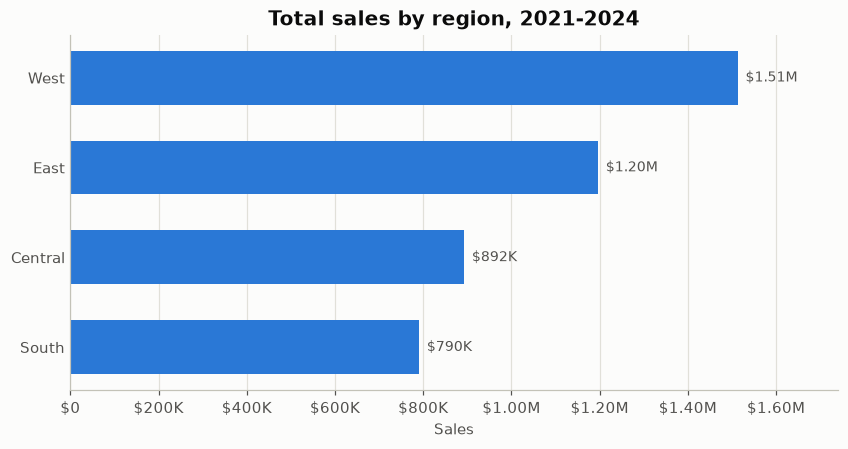

In [5]:
_ = eda.plot_sales_by_region(df)

| | |
|---|---|
| **Business question** | Q1 — Which region generates the highest sales? |
| **Variables** | `Region` (categorical), `Sales` (numeric, summed) |
| **Why this chart type** | Comparing one number across a few categories → **bar chart**. Horizontal bars keep labels readable; sorted so the ranking is instant. |
| **What it shows** | West leads with ≈ $1.51M (34% of sales), then East $1.20M, Central $0.89M, South $0.79M. |
| **How to read it** | Longer bar = more revenue. Labels give exact values. |
| **Possible implication** | West and East together produce ~62% of revenue — they are the core markets. |

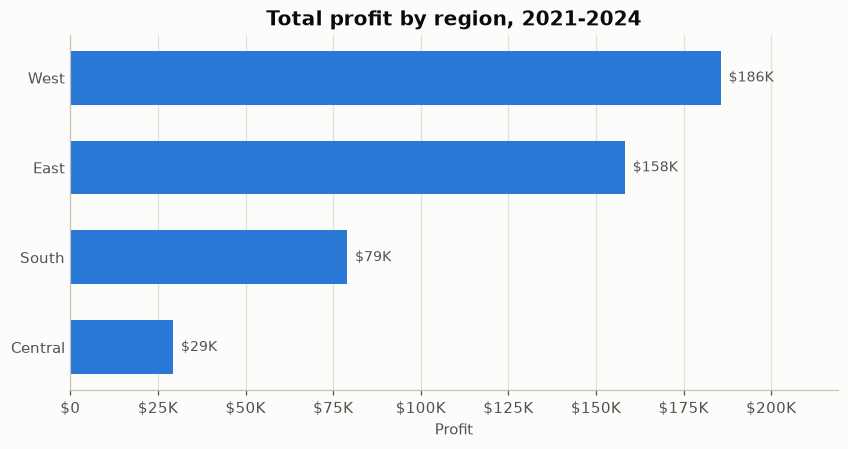

In [6]:
_ = eda.plot_profit_by_region(df)

| | |
|---|---|
| **Business question** | Q2 — Which region generates the highest profit? |
| **Variables** | `Region`, `Profit` (summed) |
| **Why this chart type** | Same comparison logic as sales, so the same chart type — this makes the two charts directly comparable. |
| **What it shows** | West earns the most profit (≈ $186K). **Central is 3rd in sales but last in profit (≈ $29K)** — less than South, which sells ~$100K less. |
| **How to read it** | Compare each region's position here with its position in the sales chart. A drop in rank = weaker profitability. |
| **Possible implication** | Central converts sales into profit much worse than the others → investigate why (see margin and discount sections). |

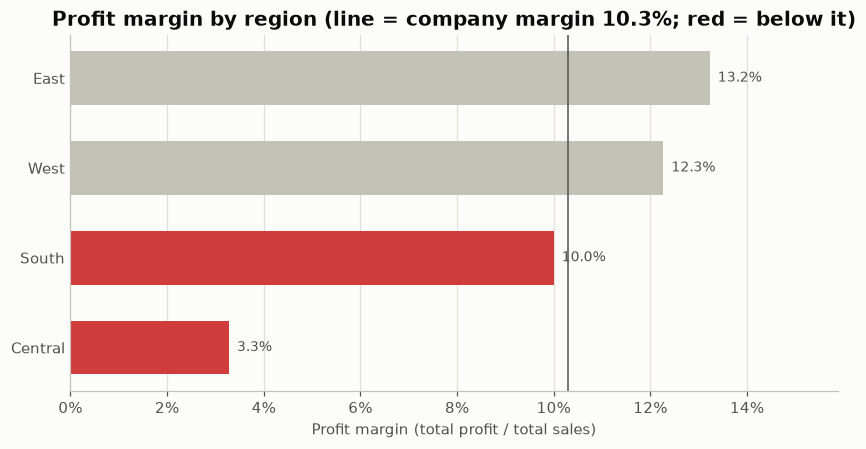

In [7]:
_ = eda.plot_regional_profit_margin(df)

| | |
|---|---|
| **Business question** | Q3 — Which region keeps the most profit per dollar of sales? |
| **Variables** | `Region`, `Profit Margin` = SUM(Profit) / SUM(Sales) |
| **Why this chart type** | Bar chart with a **reference line at the company margin**, so 'above/below average' is visible without mental arithmetic. Red is used only for 'below company margin'. |
| **What it shows** | East 13.2% and West 12.3% are above the 10.3% company margin; South is ~10.0%; **Central is 3.3%**. |
| **How to read it** | Bars left of the line are dragging the company margin down. |
| **Possible implication** | Central's margin is about a quarter of East's. Even a partial recovery there would lift company profit noticeably. |

**Observed fact:** Central's *sales* are normal-sized, but its *margin* is far below every other region.
**Not yet known:** *why*. Candidate explanations to test later: (a) Central sells a less profitable product mix, (b) Central gives bigger discounts, (c) Central has higher costs (not in our data → cannot be tested here).

---
## 2 · Time analysis

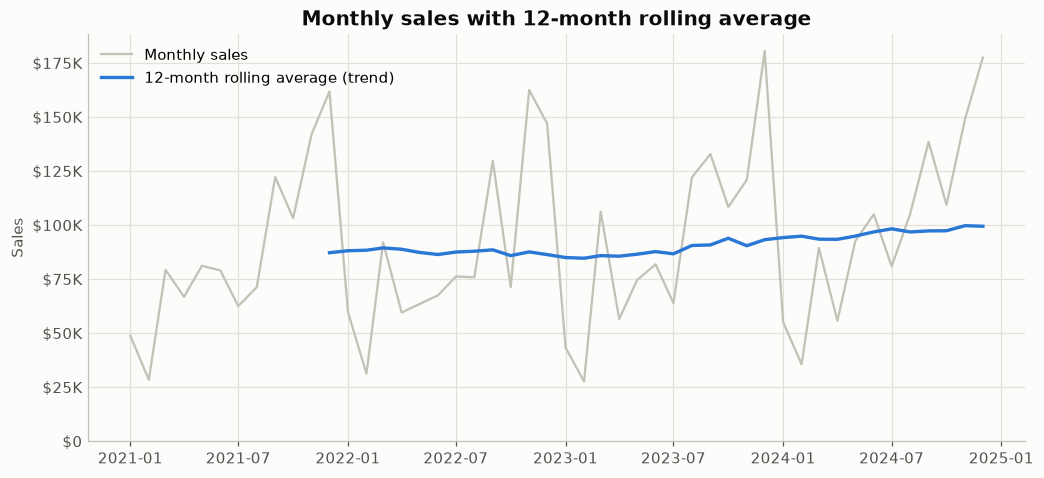

In [8]:
_ = eda.plot_monthly_sales(df)

| | |
|---|---|
| **Business question** | Q9/Q10 — How are sales changing over time? |
| **Variables** | `Year-Month`, `Sales` |
| **Why this chart type** | Time on the x-axis → **line chart**, because the order of months matters and lines show direction. A 12-month **rolling average** is added because monthly values swing heavily with seasons; averaging 12 months removes the seasonal effect and leaves the trend. |
| **What it shows** | Grey line: large repeating peaks every autumn/winter. Blue line: flat through 2022, then rising from 2023 onward. |
| **How to read it** | Judge growth from the **blue** line, not by comparing two random grey points (e.g. Dec vs Jan would always look like a collapse). |
| **Possible implication** | Sales are growing again since 2023. Seasonality must be considered in staffing, inventory and target-setting. |

In [9]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
yearly["Profit Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["YoY Sales %"] = yearly["Sales"].pct_change() * 100
yearly["YoY Profit %"] = yearly["Profit"].pct_change() * 100
yearly

,Sales,Profit,Orders,Profit Margin %,YoY Sales %,YoY Profit %
Year,,,,,,
2021,"1,045,575.54","112,678.34",1184,10.78,NaN,NaN
2022,"1,035,179.93","111,076.75",1260,10.73,-0.99,-1.42
2023,"1,117,829.65","118,071.19",1353,10.56,7.98,6.30
2024,"1,192,590.88","110,241.76",1393,9.24,6.69,-6.63


**🚩 Important observation:** in **2024 sales grew +6.7% but profit fell −6.6%**, and margin dropped from 10.6% to 9.2%. This is "growth without profit" — a sales-only dashboard would have reported 2024 as a good year. Notebook 04 investigates the cause.

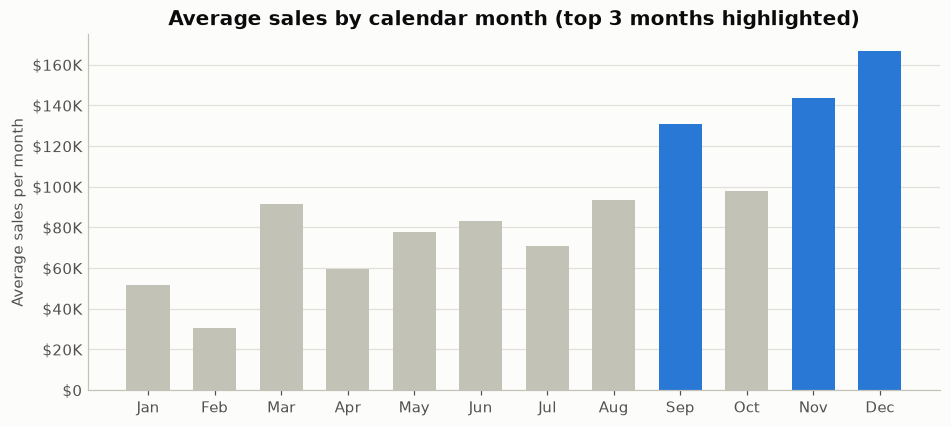

In [10]:
_ = eda.plot_seasonality(df)

| | |
|---|---|
| **Business question** | Q9 — Which months have the highest sales? |
| **Variables** | `Month Number`, average monthly `Sales` across 2021–2024 |
| **Why this chart type** | **Bar chart** of calendar months. We use the *average across years* so that one exceptional year cannot dominate. Top 3 months highlighted; the rest muted so the eye goes to the answer. |
| **What it shows** | December, November and September are the peaks; February and January are the weakest. |
| **How to read it** | Each bar = a typical month of that name. Highlighted bars are the top 3. |
| **Possible implication** | Q4 alone delivers ~37% of annual sales. Promotions and stock should be planned before September; January–February are the natural window for maintenance, training or targeted demand campaigns. |

In [11]:
eda.seasonality(df).T

Month Number,1,2,3,4,5,6,7,8,9,10,11,12
Avg Monthly Sales,"51,671.70","30,626.30","91,656.40","59,572.20","77,854.70","83,246.40","70,795.80","93,477.00","130,745.70","97,987.40","143,516.30","166,644.10"
Index vs Average,56.50,33.50,100.20,65.10,85.10,91.00,77.40,102.20,142.90,107.10,156.90,182.20


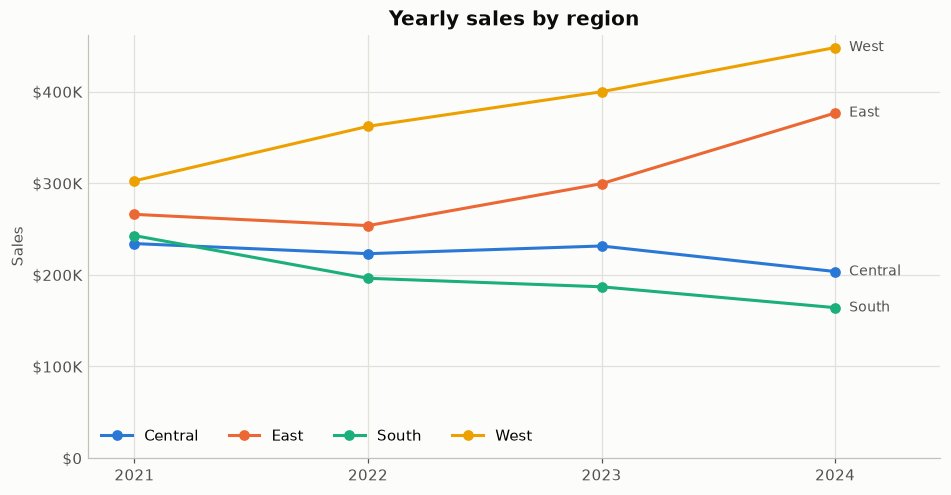

In [12]:
_ = eda.plot_yearly_sales_by_region(df)

| | |
|---|---|
| **Business question** | Q8/Q11 — Which regions are growing or declining? |
| **Variables** | `Year`, `Region`, `Sales` |
| **Why this chart type** | Multiple series over time → **multi-line chart**, one colour per region (the same region colour is used everywhere). Lines are labelled at the end so no legend lookup is needed. |
| **What it shows** | West and East grow steadily; **South declines every year**; Central is flat then falls in 2024. |
| **How to read it** | Slope = growth rate. Compare where each line starts and ends. |
| **Possible implication** | The company's growth comes entirely from West and East. South and Central need a diagnosis (market, competition, sales coverage). |

In [13]:
eda.yearly_pivot(df, "Region", "Sales")

Year,2021,2022,2023,2024,YoY % (2024),CAGR % (2021-2024)
Region,,,,,,
Central,"234,133.58","223,094.23","231,487.81","203,602.68",-12.05,-4.55
East,"266,009.22","253,729.35","299,519.77","376,666.58",25.76,12.29
South,"242,839.07","196,229.20","186,946.14","164,173.07",-12.18,-12.23
West,"302,593.67","362,127.15","399,875.93","448,148.55",12.07,13.99


**CAGR (Compound Annual Growth Rate)** = (last / first)^(1 / years) − 1. It summarises a multi-year trend as one steady yearly rate, which is fairer than comparing just two adjacent years.

South: −12.2% per year. West: +14.0% per year.

In [14]:
eda.yearly_pivot(df, "Region", "Profit")

Year,2021,2022,2023,2024,YoY % (2024),CAGR % (2021-2024)
Region,,,,,,
Central,"13,838.79","8,498.88","7,701.14",-744.27,-109.66,NaN
East,"34,642.60","33,613.45","44,700.59","45,265.37",1.26,9.32
South,"28,905.57","21,436.97","14,913.56","13,725.75",-7.96,-21.98
West,"35,291.38","47,527.45","50,755.90","51,994.91",2.44,13.79


Central's profit fell every year and turned **negative in 2024**, even though its sales were still ≈ $204K.

---
## 3 · Product analysis

In [15]:
eda.summarize_by(df, "Category")

,Sales,Profit,Quantity,Orders,Profit Margin %,Sales Share %,Effective Discount %
Category,,,,,,,
Technology,"1,821,185.97","252,948.63",8811,1853,13.89,41.47,13.89
Furniture,"1,452,790.28","-1,797.48",10786,2024,-0.12,33.08,18.61
Office Supplies,"1,117,199.75","200,916.89",37106,4089,17.98,25.44,13.85


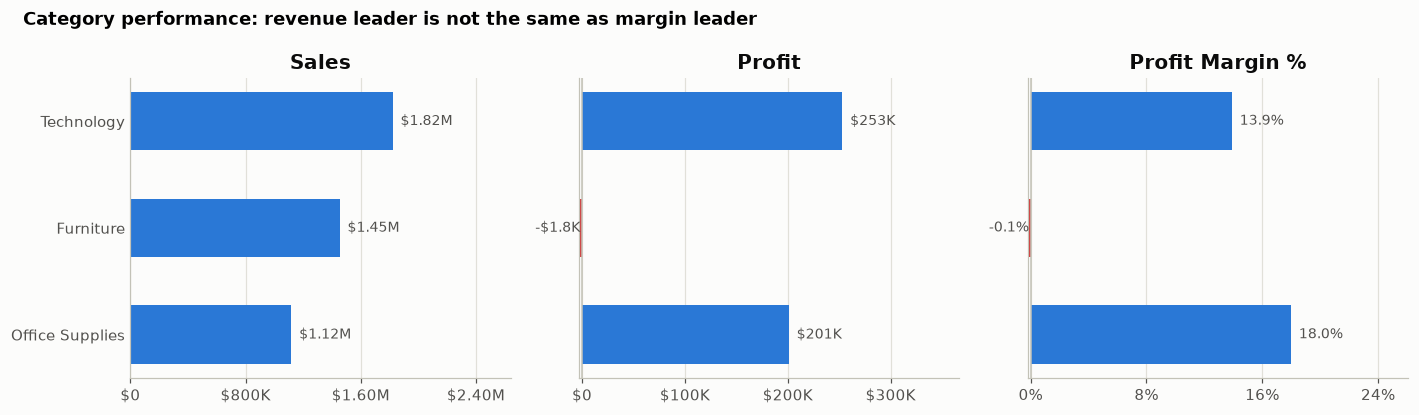

In [16]:
_ = eda.plot_category_analysis(df)

| | |
|---|---|
| **Business question** | Q4/Q5 — Which category generates the most revenue, and the most profit? |
| **Variables** | `Category`, `Sales`, `Profit`, margin |
| **Why this chart type** | Three small panels with the **same category order** instead of one chart with two y-axes. Dual-axis charts invent visual correlations because the two scales are arbitrary; side-by-side panels avoid that. |
| **What it shows** | Technology leads in sales and profit. Office Supplies is smallest in sales but has the **best margin (18%)**. **Furniture sells $1.45M but makes a small loss overall.** |
| **How to read it** | Read across a row: the same category in all three panels. |
| **Possible implication** | Revenue size and profitability are different things. Furniture needs attention despite healthy sales. |

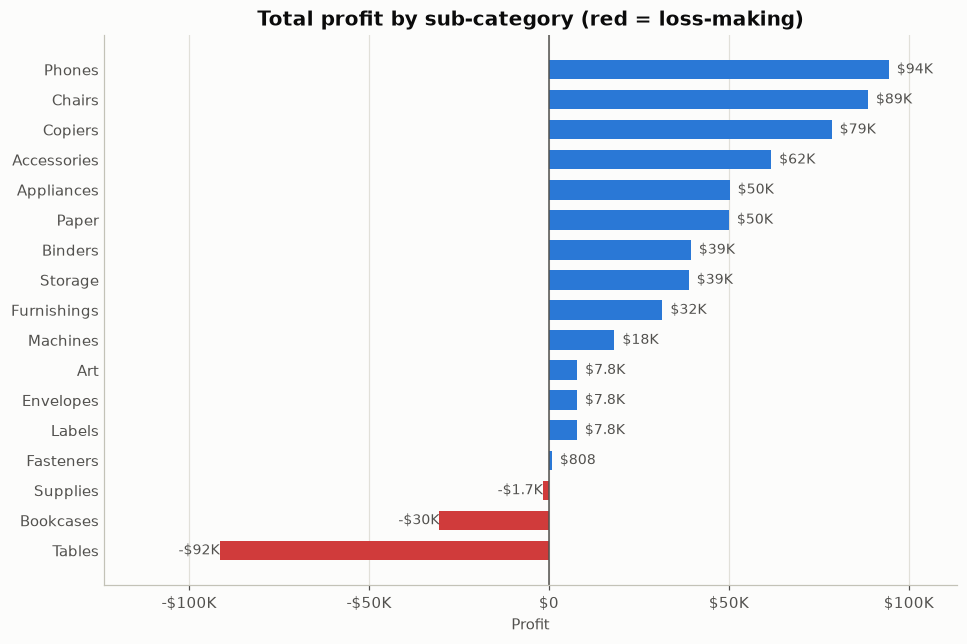

In [17]:
_ = eda.plot_subcategory_profit(df)

| | |
|---|---|
| **Business question** | Q12/Q13 — Which sub-categories make or lose money? |
| **Variables** | `Sub-Category`, `Profit` |
| **Why this chart type** | 17 categories → **horizontal bar** (long labels fit). Sorted by profit; red reserved for losses so loss-makers stand out. |
| **What it shows** | Phones, Chairs and Copiers are the top profit sources. **Tables (−$91.5K) and Bookcases (−$30.4K)** lose money; Supplies loses slightly. |
| **How to read it** | Bars left of zero are losses. |
| **Possible implication** | Tables and Bookcases wipe out the profit made by Chairs and Furnishings — that is why Furniture as a whole is break-even. |

In [18]:
eda.top_n(df, "Product Name", n=10)

,Sales,Profit,Profit Margin %,Orders
Product Name,,,,
Orbit Smartphone L502,"142,830.00","6,864.48",4.81,77
Folding Work Table C380,"111,165.42","-23,455.42",-21.10,77
Heavy-Duty Microwave Z820,"110,411.91","12,928.10",11.71,89
Executive Chair V504,"107,447.71","16,403.74",15.27,88
Comfort+ Chair M977,"105,214.93","14,348.48",13.64,79
Orbit IP Phone N152,"98,768.07","8,245.64",8.35,79
ErgoFlex Guest Chair P494,"97,277.75","6,175.88",6.35,94
Executive Office Chair K304,"95,515.01","11,458.39",12.00,78
Mono Copier C616,"93,507.31","15,912.40",17.02,34


In [19]:
eda.top_n(df, "Product Name", metric="Profit", n=10, ascending=True)

,Sales,Profit,Profit Margin %,Orders
Product Name,,,,
Round Table M702,"89,287.20","-26,412.30",-29.58,68
Folding Work Table C380,"111,165.42","-23,455.42",-21.10,77
Training Table D848,"61,013.04","-16,693.23",-27.36,61
Rectangular Table R527,"53,109.62","-10,835.78",-20.40,60
3-Shelf Shelving Unit M597,"55,743.08","-10,751.42",-19.29,51
Open Shelving Unit T373,"54,920.34","-9,872.50",-17.98,52
Folding Work Table K823,"38,252.15","-8,767.65",-22.92,60
Training Table W359,"40,068.39","-5,356.73",-13.37,65
Corner Shelving Unit B787,"36,748.94","-5,353.79",-14.57,46


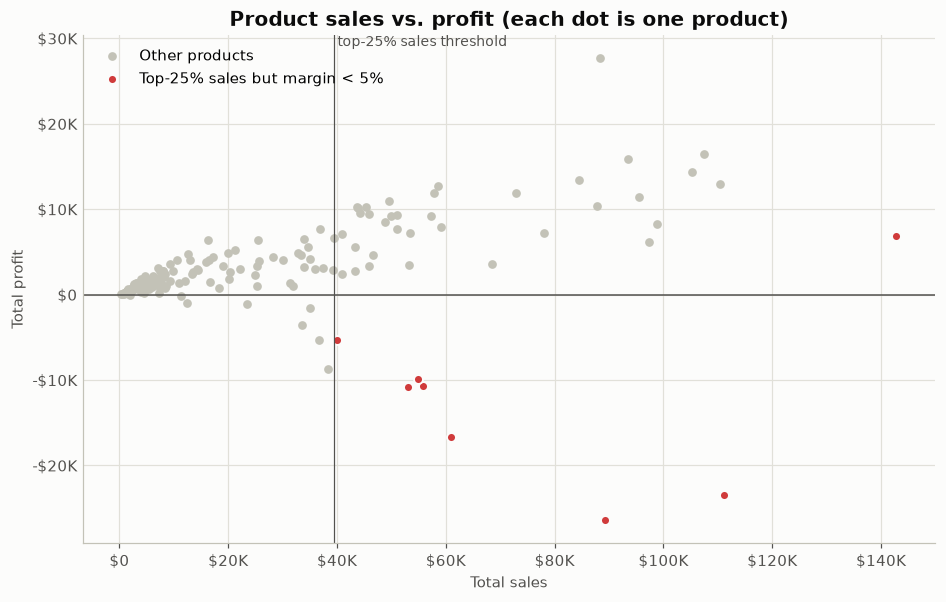

In [20]:
_ = eda.plot_product_sales_vs_profit(df)

| | |
|---|---|
| **Business question** | Q6 — Which products have high sales but low profit? |
| **Variables** | per product: total `Sales` (x), total `Profit` (y) |
| **Why this chart type** | Two numeric measures per item → **scatter plot**. Each dot is one product. A vertical line marks the top-25% sales threshold; a horizontal line marks zero profit. |
| **What it shows** | Most products sit on a rising band (more sales → more profit). A cluster of high-selling products sits **below zero**. |
| **How to read it** | Bottom-right area = sells a lot but loses money — the most dangerous products because they look successful on a sales report. |
| **Possible implication** | These products need pricing/discount review first. They are all Tables or Bookcases except one smartphone with a thin 4.8% margin. |

In [21]:
eda.high_sales_low_profit(df)

,Sales,Profit,Profit Margin %,Effective Discount %
Product Name,,,,
Round Table M702,"89,287.20","-26,412.30",-29.58,27.85
Folding Work Table C380,"111,165.42","-23,455.42",-21.10,24.30
Training Table D848,"61,013.04","-16,693.23",-27.36,25.71
Rectangular Table R527,"53,109.62","-10,835.78",-20.40,25.76
3-Shelf Shelving Unit M597,"55,743.08","-10,751.42",-19.29,22.09
Open Shelving Unit T373,"54,920.34","-9,872.50",-17.98,23.30
Training Table W359,"40,068.39","-5,356.73",-13.37,24.04
Orbit Smartphone L502,"142,830.00","6,864.48",4.81,14.68


---
## 4 · Customer analysis

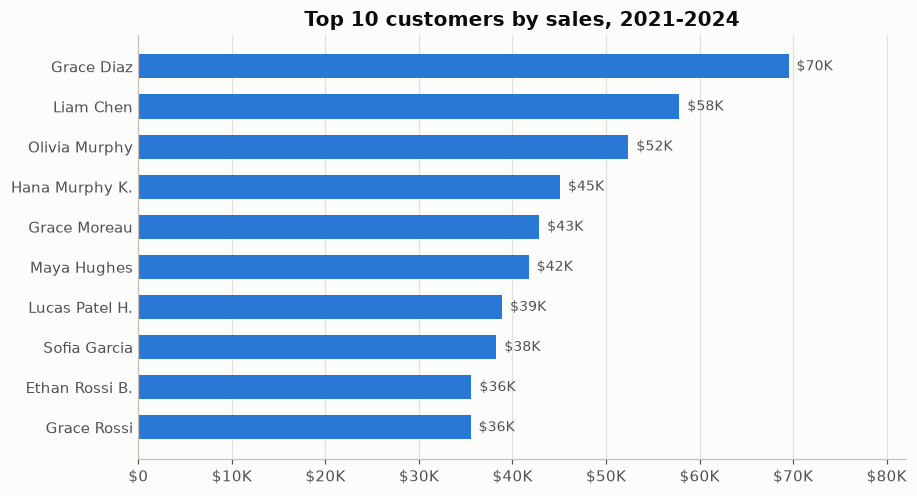

In [22]:
_ = eda.plot_top_customers(df)

| | |
|---|---|
| **Business question** | Q7 — Which customers contribute the most revenue? |
| **Variables** | `Customer Name`, `Sales` |
| **Why this chart type** | Ranking → sorted **horizontal bar**. |
| **What it shows** | The top customer bought ≈ $69.5K over four years. The top 10 together are ~10% of sales. |
| **How to read it** | Longer bar = bigger customer. |
| **Possible implication** | No single customer is critical, but see the concentration numbers below. |

In [23]:
cust = df.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False)
n = len(cust)
pd.Series({
    "Customers": n,
    "Top 10% share of sales %": cust.head(int(n * 0.10)).sum() / cust.sum() * 100,
    "Top 20% share of sales %": cust.head(int(n * 0.20)).sum() / cust.sum() * 100,
    "Median customer lifetime sales $": cust.median(),
}).to_frame("value")

,value
Customers,741.00
Top 10% share of sales %,36.78
Top 20% share of sales %,54.26
Median customer lifetime sales $,"3,947.95"


**Pareto check:** the top 20% of customers generate ~54% of sales — a meaningful concentration, though weaker than the classic "80/20 rule". Retaining the top 150 customers matters more than acquiring many small ones.

**Profit ≠ revenue at customer level:** in the top-10 list, `Maya Hughes` bought $41.7K but generated only $472 profit (1.1% margin) — a customer who mostly buys at deep discounts.

In [24]:
eda.top_n(df, "Customer Name", n=10)

,Sales,Profit,Profit Margin %,Orders
Customer Name,,,,
Grace Diaz,"69,516.61","6,839.51",9.84,63
Liam Chen,"57,842.62","3,416.89",5.91,70
Olivia Murphy,"52,395.72","6,735.93",12.86,56
Hana Murphy K.,"45,073.79","4,562.05",10.12,41
Grace Moreau,"42,853.29","6,900.96",16.10,48
Maya Hughes,"41,729.01",471.96,1.13,37
Lucas Patel H.,"38,890.14","3,550.39",9.13,38
Sofia Garcia,"38,273.16","4,325.50",11.30,41
Ethan Rossi B.,"35,615.23","5,848.15",16.42,31


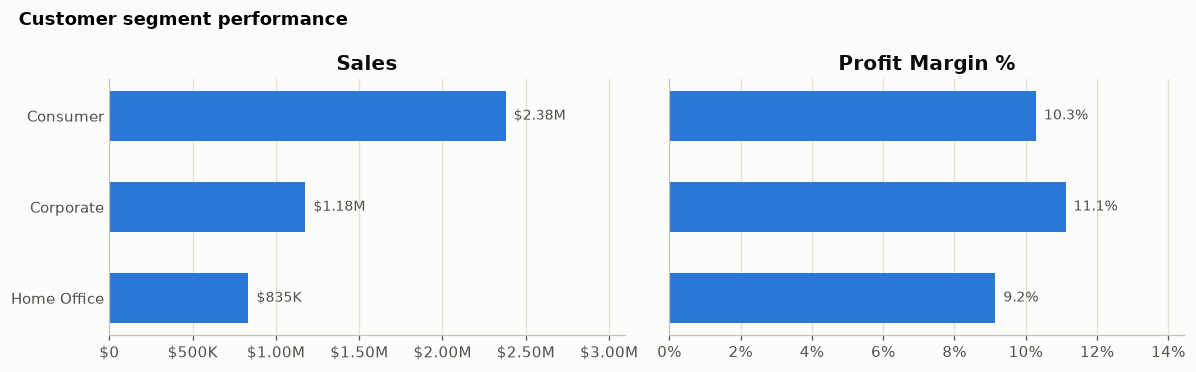

In [25]:
_ = eda.plot_segment_performance(df)

| | |
|---|---|
| **Business question** | Q14 — Which customer segment generates the most sales, and at what margin? |
| **Variables** | `Segment`, `Sales`, margin |
| **Why this chart type** | Two side-by-side bar panels (no dual axis). |
| **What it shows** | Consumer brings 54% of sales; Corporate has the best margin (11.1%); Home Office the lowest (9.2%). |
| **How to read it** | Compare bar lengths within each panel. |
| **Possible implication** | Segment margins are close (9–11%). Segment is **not** the main driver of profitability — region, product and discount are. |

---
## 5 · Discount analysis — Discount → Sales → Profit

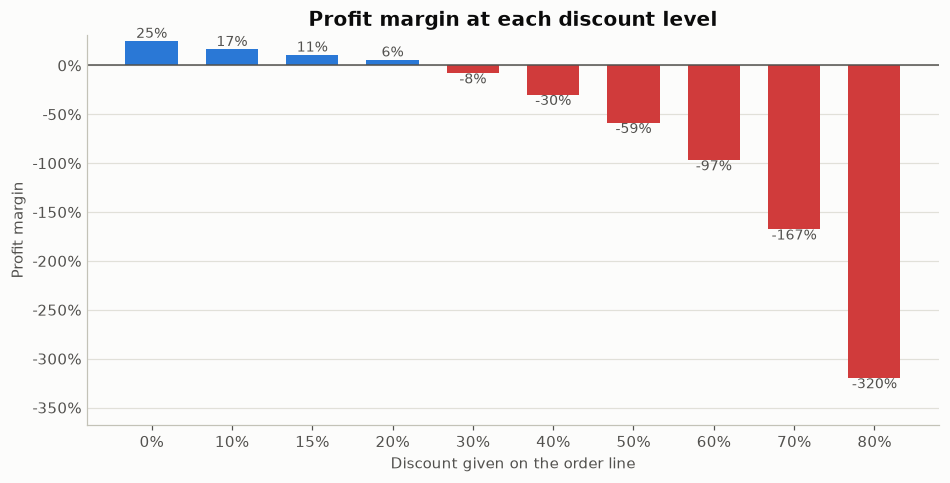

In [26]:
_ = eda.plot_discount_vs_margin(df)

| | |
|---|---|
| **Business question** | Q8 — How is discount level associated with profitability? |
| **Variables** | `Discount` level, margin = SUM(Profit)/SUM(Sales) at that level |
| **Why this chart type** | Discount has only 10 fixed levels, so an **ordered bar chart** of aggregated margin is clearer than a scatter of 11,000 overlapping dots. |
| **What it shows** | Margin falls steadily as discount rises: ~25% with no discount, ~6% at 20%, and **every level from 30% upward loses money overall**. |
| **How to read it** | Bars below zero = that discount level loses money in total. |
| **Possible implication** | There is a clear threshold between 20% and 30%. Discounts of 30%+ should require approval. |

In [27]:
eda.discount_impact(df)

,Lines,Sales,Profit,Profit Margin %,% Lines Loss-Making
Discount,,,,,
0.00,5208,"2,277,898.26","566,357.12",24.86,0.00
0.10,730,"283,161.30","46,790.17",16.52,3.42
0.15,454,"187,955.67","20,303.40",10.80,7.93
0.20,3225,"1,175,525.02","67,973.71",5.78,10.95
0.30,545,"160,005.27","-12,346.45",-7.72,51.38
0.40,414,"126,338.63","-37,606.32",-29.77,82.85
0.50,319,"77,585.02","-45,411.93",-58.53,95.30
0.60,288,"58,162.90","-56,211.46",-96.64,100.00
0.70,148,"29,287.29","-49,032.20",-167.42,100.00


In [28]:
eda.discount_correlation(df)

Pearson    -0.81
Spearman   -0.72
dtype: float64

**Correlation** measures how strongly two variables move together, from −1 (perfectly opposite) to +1 (perfectly together).
* Pearson −0.81 and Spearman −0.72 → a **strong negative association** between discount and line margin.
* ⚠️ **Association, not proven cause.** Here the mechanism is arithmetic (a discount lowers the price while the cost stays the same), so causation is plausible. But deep discounts may also be given on items that were *already* hard to sell, so the discount could partly be a symptom. A controlled pricing test would be needed to measure the true effect on volume.

In [29]:
region_disc = eda.summarize_by(df, "Region")[["Effective Discount %", "Profit Margin %"]]
region_disc["% lines with 30%+ discount"] = df.groupby("Region")["Discount"].apply(lambda s: (s >= 0.3).mean() * 100)
region_disc.sort_values("Effective Discount %", ascending=False)

,Effective Discount %,Profit Margin %,% lines with 30%+ discount
Region,,,
Central,21.51,3.28,27.71
South,15.01,10.00,15.27
West,13.47,12.27,10.83
East,13.46,13.23,13.56


**Effective discount %** = total discount given ÷ total list-price value. It is weighted by money, so it is better than a simple average of the discount column.

**Observed:** Central gives away **21.5%** of list value vs ~13.5% in East/West, and 28% of Central's lines carry a 30%+ discount (vs ~13% elsewhere).

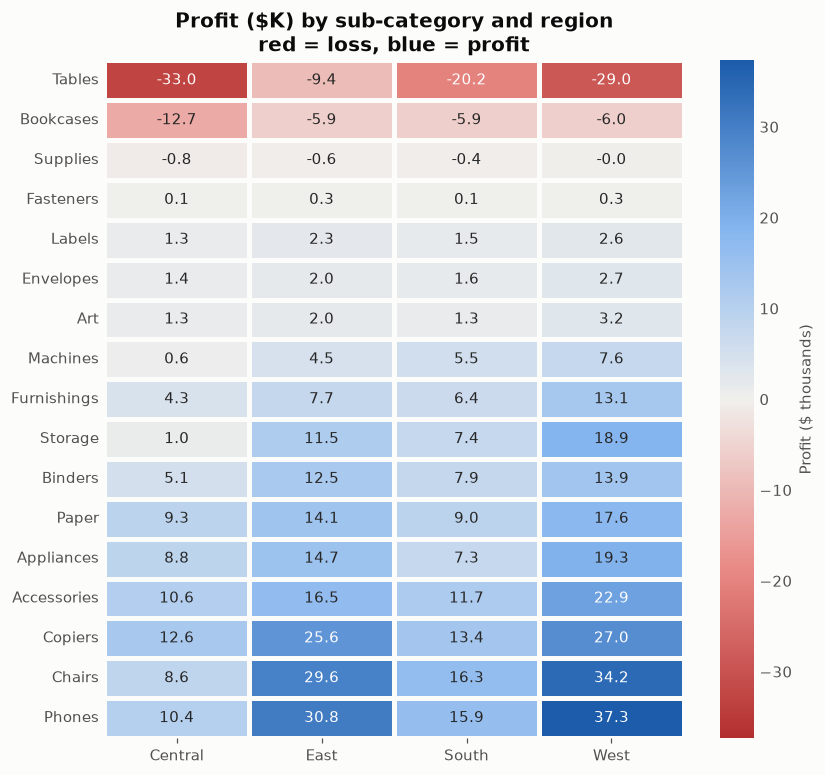

In [30]:
_ = eda.plot_region_subcategory_heatmap(df)

| | |
|---|---|
| **Business question** | Q15 — Where exactly is profit being lost? |
| **Variables** | `Sub-Category` × `Region`, `Profit` |
| **Why this chart type** | Two categorical dimensions and one value → **heatmap**. A **diverging** colour scale (red = loss, grey = zero, blue = profit) shows the *sign* of each cell instantly; numbers are printed so colour is never the only cue. |
| **What it shows** | Tables lose money in **every** region; Bookcases too. Central is the weakest column across almost all sub-categories. |
| **How to read it** | Red cells = loss-making combinations; deeper colour = larger amount. |
| **Possible implication** | Two separate problems: a **product problem** (Tables/Bookcases everywhere) and a **regional problem** (Central across the board). |

### Testing the two Central hypotheses
**(a) Product mix?** If Central simply sold more loss-making products, its margin *within each sub-category* would be similar to other regions.

In [31]:
t = df.groupby(["Sub-Category", "Region"])[["Discount Amount", "Gross Sales"]].sum()
eff = (t["Discount Amount"] / t["Gross Sales"] * 100).unstack().round(1)
print("Sub-categories where Central has the HIGHEST effective discount:",
      (eff.idxmax(axis=1) == "Central").sum(), "of", len(eff))
eff

Sub-categories where Central has the HIGHEST effective discount: 15 of 17


Region,Central,East,South,West
Sub-Category,,,,
Accessories,16.90,12.80,10.50,11.60
Appliances,15.90,10.60,13.10,8.60
Art,18.10,13.30,15.10,9.70
Binders,24.60,16.20,13.80,15.60
Bookcases,27.10,19.50,22.40,16.90
Chairs,20.40,12.10,13.10,12.00
Copiers,15.70,12.60,14.40,11.40
Envelopes,13.10,10.50,10.00,14.60
Fasteners,12.00,12.40,14.50,11.80


In [32]:
central = df[df["Region"] == "Central"]
pd.DataFrame({
    "Central lines": [central.loc[central["Discount"] < 0.3, "Profit"].sum() / central.loc[central["Discount"] < 0.3, "Sales"].sum() * 100,
                      central.loc[central["Discount"] >= 0.3, "Profit"].sum()],
    "All other regions": [df.loc[(df["Region"] != "Central") & (df["Discount"] < 0.3), "Profit"].sum()
                          / df.loc[(df["Region"] != "Central") & (df["Discount"] < 0.3), "Sales"].sum() * 100,
                          df.loc[(df["Region"] != "Central") & (df["Discount"] >= 0.3), "Profit"].sum()],
}, index=["Margin % on lines with < 30% discount", "Total profit on lines with 30%+ discount ($)"]).round(1)

,Central lines,All other regions
Margin % on lines with < 30% discount,17.40,18.00
Total profit on lines with 30%+ discount ($),"-96,101.00","-153,255.30"


**Result:** Central discounts more heavily in 15 of 17 sub-categories, and on lines with normal (<30%) discounts **Central's margin (~17%) is similar to the other regions**. Its 30%+ lines lose ≈ $96K.

**Interpretation (hypothesis, not proof):** Central's low margin is associated mainly with its **discounting behaviour**, not with selling different products. Possible causes to investigate with the business: regional pricing authority, sales incentives paid on revenue rather than profit, or local competition forcing price cuts.

---
## EDA summary — observed facts only

| # | Fact |
|---|---|
| 1 | West has the highest sales (≈ $1.51M) and profit (≈ $186K). |
| 2 | East has the highest margin (13.2%); Central the lowest (3.3%). |
| 3 | 2024: sales +6.7%, profit −6.6%; margin fell to 9.2%. |
| 4 | South sales fell every year (CAGR −12.2%); Central's profit turned negative in 2024. |
| 5 | Sales peak in Dec, Nov and Sep; Q4 ≈ 37% of annual sales. |
| 6 | Technology: largest sales and profit. Office Supplies: best margin. Furniture: ≈ break-even. |
| 7 | Tables (−$91.5K) and Bookcases (−$30.4K) are loss-making in every region. |
| 8 | Every discount level of 30% or more is loss-making in total. |
| 9 | Central has the highest effective discount (21.5%) and the most 30%+ lines. |
| 10 | Top 20% of customers = ~54% of sales. |

Explanations and recommendations are developed in **04_business_analysis.ipynb**.